# Notebook: Dijkstra und A\*

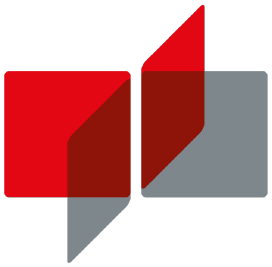Kapitel
05 – Kürzeste Wege · ca. 20 Minuten  
<span style="color:#58636C">Fortgeschrittene Algorithmen · M.
Bergau</span>

Im Notebook zu BFS und DFS haben Sie gesehen: Welche Suche entsteht,
hängt nur davon ab, welcher Knoten als Nächstes aus `offen` genommen
wird. Hier geht es weiter. Mit einer **Priority Queue** wird aus
demselben Gerüst erst Dijkstra und dann A\*. Gesucht ist der billigste
Weg über eine Karte mit Mauern und Matsch.

| Teil  | Inhalt                                   | Zeit  |
|:------|:-----------------------------------------|:------|
| 0     | Priority Queue und Karte laden           | 3 min |
| 1     | Dijkstra                                 | 8 min |
| 2     | Eine Heuristik                           | 2 min |
| 3     | A\*                                      | 4 min |
| 4     | Vergleich und Fragen                     | 3 min |
| Bonus | Greedy-Suche, zu optimistische Heuristik | –     |

## Teil 0: Priority Queue und Karte

Zur Erinnerung das Gerüst aus dem letzten Notebook. Heute geht es um die
beiden unteren Zeilen:

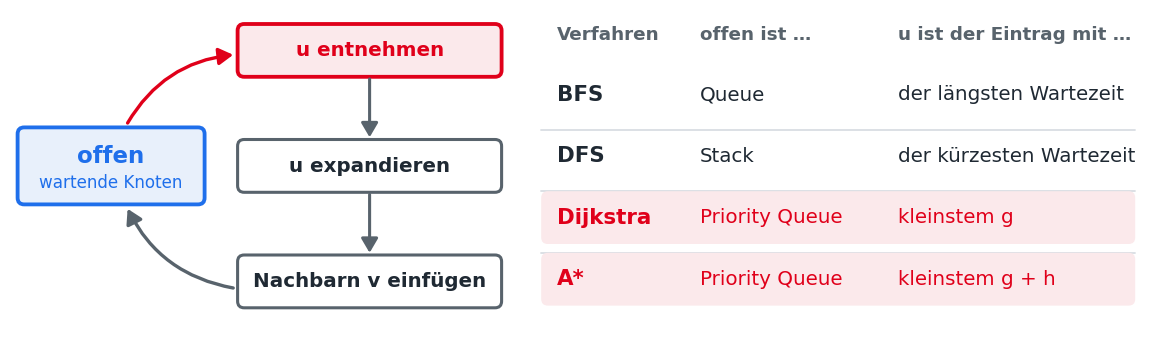

Eine Priority Queue gibt immer den Eintrag mit der **kleinsten
Priorität** heraus, egal wann er eingefügt wurde. Python hat dafür das
Modul `heapq`. Es arbeitet auf einer gewöhnlichen Liste, die intern als
Baum geordnet ist:

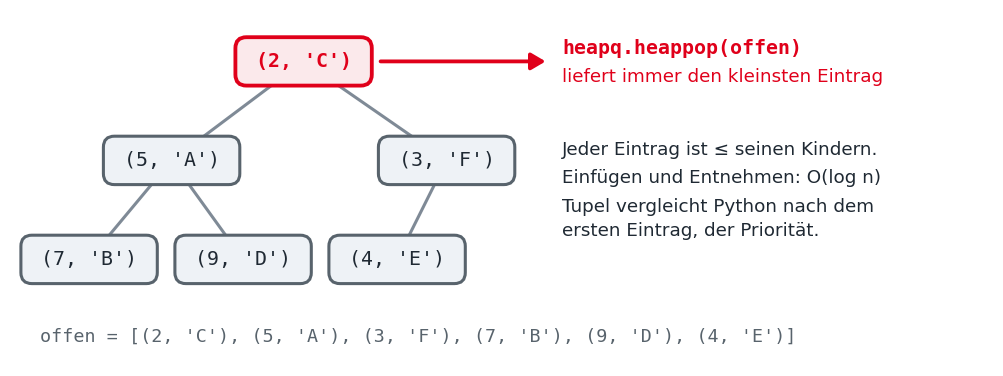

In [ ]:
import heapq

offen = []
heapq.heappush(offen, (5, "A"))     # Einträge sind Tupel (Priorität, Knoten)
heapq.heappush(offen, (2, "C"))
heapq.heappush(offen, (7, "B"))
print(heapq.heappop(offen))         # (2, 'C'): der kleinste Eintrag
print(heapq.heappop(offen))         # (5, 'A')

Die Karte ist ein Gitter. Ein Feld ist ein Tupel `(zeile, spalte)`. Man
geht nach oben, unten, links oder rechts. Ein freies Feld zu betreten
kostet 1, ein Matschfeld 5, durch Mauern geht es nicht. Hier ist nichts
zu tun, führen Sie die Zelle einfach aus.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

PLAN = [
    "....................",
    "....................",
    "....#...~~~~........",
    "....#...~~~~........",
    "....#...~~~~........",
    "..S.#...~~~~.....Z..",
    "....#...~~~~........",
    "....#...~~~~........",
    "........~~~~........",
    "....................",
    "....................",
]


class Karte:
    """Gitter aus Feldern (zeile, spalte): '.' frei, '~' Matsch, '#' Mauer."""

    KOSTEN = {".": 1, "S": 1, "Z": 1, "~": 5}

    def __init__(self, plan):
        self.plan = plan
        self.zeilen, self.spalten = len(plan), len(plan[0])
        for z, zeile in enumerate(plan):
            for s, zeichen in enumerate(zeile):
                if zeichen == "S":
                    self.start = (z, s)
                if zeichen == "Z":
                    self.ziel = (z, s)

    def nachbarn(self, u):
        """Liste von (v, kosten) für alle Felder neben u, die keine Mauer sind.
        kosten ist der Preis dafür, v zu betreten."""
        z, s = u
        ergebnis = []
        for dz, ds in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            v = (z + dz, s + ds)
            if 0 <= v[0] < self.zeilen and 0 <= v[1] < self.spalten:
                zeichen = self.plan[v[0]][v[1]]
                if zeichen != "#":
                    ergebnis.append((v, self.KOSTEN[zeichen]))
        return ergebnis

    def zeichne(self, erledigt=(), weg=(), titel="", ax=None):
        """Karte zeichnen. Blau: expandierte Felder. Rot: gefundener Weg."""
        allein = ax is None
        if allein:
            _, ax = plt.subplots(figsize=(8, 4.6))
        farbe = {".": "white", "S": "white", "Z": "white", "~": "#d9c3a5", "#": "#4a525a"}
        for z in range(self.zeilen):
            for s in range(self.spalten):
                ax.add_patch(Rectangle((s, z), 1, 1, fc=farbe[self.plan[z][s]],
                                       ec="#D9DEE3", lw=0.8))
                if (z, s) in erledigt:
                    ax.add_patch(Rectangle((s, z), 1, 1, fc="#1f6feb", alpha=0.28, lw=0))
        if weg:
            ax.plot([s + 0.5 for z, s in weg], [z + 0.5 for z, s in weg],
                    color="#E0001A", lw=3)
        for (z, s), t in ((self.start, "S"), (self.ziel, "Z")):
            ax.text(s + 0.5, z + 0.5, t, ha="center", va="center", fontsize=13,
                    fontweight="bold", color="#1f2933")
        if erledigt:
            titel = f"{titel}: {len(erledigt)} Felder expandiert"
        ax.set_title(titel)
        ax.set_xlim(0, self.spalten)
        ax.set_ylim(self.zeilen, 0)
        ax.set_aspect("equal")
        ax.set_axis_off()
        if allein:
            plt.show()


def weg(vorgaenger, ziel):
    """Weg vom Start zum Ziel, rückwärts über die Vorgänger aufgebaut."""
    pfad = []
    u = ziel
    while u is not None:
        pfad.append(u)
        u = vorgaenger[u]
    return pfad[::-1]


karte = Karte(PLAN)
print("Start:", karte.start, "  Ziel:", karte.ziel)
print("Nachbarn von", karte.start, ":", karte.nachbarn(karte.start))
karte.zeichne(titel="Die Karte (braun: Matsch, dunkel: Mauer)")

## Teil 1: Dijkstra

Dijkstra merkt sich für jedes Feld `v` die bisher besten bekannten
Kosten `g[v]` vom Start. `offen` ist eine Priority Queue mit Einträgen
`(g, Feld)`. Entnommen wird also immer das Feld mit den kleinsten
Kosten. Beim Expandieren von `u` prüft man jeden Nachbarn `v`: Ist der
Weg über `u` billiger als alles bisher Bekannte, wird `g[v]` verbessert.

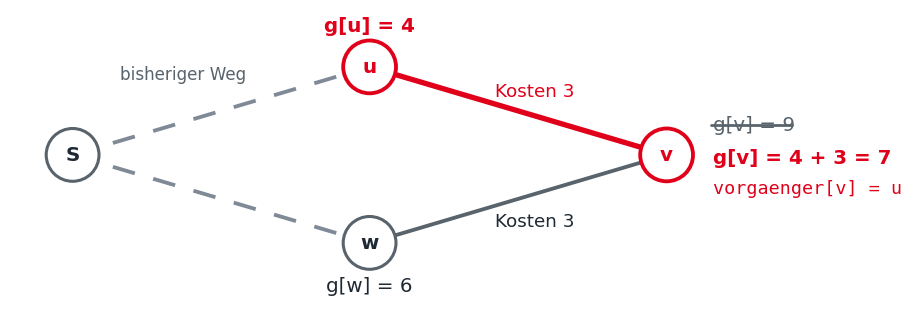

Ein Feld kann dadurch mehrfach in `offen` stehen. Der veraltete Eintrag
wird beim Entnehmen einfach übersprungen, wie bei BFS.

**Aufgabe:** Ergänzen Sie die beiden `TODO`-Stellen.

In [ ]:
def dijkstra(karte, start, ziel):
    g = {start: 0}               # beste bisher bekannte Kosten vom Start
    vorgaenger = {start: None}   # über welches Feld man am billigsten kommt
    offen = [(0, start)]         # Priority Queue mit Einträgen (Priorität, Feld)
    erledigt = set()             # bereits expandierte Felder

    while offen:
        # TODO 1: den Eintrag mit der kleinsten Priorität entnehmen (heapq.heappop)
        prio, u = ...

        if u in erledigt:        # veralteter Eintrag: u ist schon erledigt
            continue
        erledigt.add(u)
        if u == ziel:
            break

        for v, kosten in karte.nachbarn(u):
            neu = g[u] + kosten
            # TODO 2: Ist v neu (v not in g) oder neu < g[v]?
            #         Dann g[v] und vorgaenger[v] setzen und (neu, v) in offen einfügen.


    return g, vorgaenger, erledigt

Test: Der billigste Weg von S nach Z kostet 23.

In [ ]:
g, vorgaenger, erledigt = dijkstra(karte, karte.start, karte.ziel)
assert karte.ziel in g, "Das Ziel wurde nie erreicht. Fehlt TODO 2?"
print("Kosten bis Z:", g[karte.ziel], "   expandierte Felder:", len(erledigt))
karte.zeichne(erledigt, weg(vorgaenger, karte.ziel), "Dijkstra")
assert g[karte.ziel] == 23, "Die Kosten sollten 23 sein."
print("✓ Dijkstra korrekt")

## Teil 2: Eine Heuristik

Dijkstra sucht in alle Richtungen, auch weg vom Ziel. A\* nimmt eine
Schätzung `h(u)` der Restkosten bis zum Ziel dazu. Auf dem Gitter bietet
sich die **Manhattan-Distanz** an: die Zahl der Schritte senkrecht plus
waagerecht, als gäbe es weder Mauer noch Matsch.

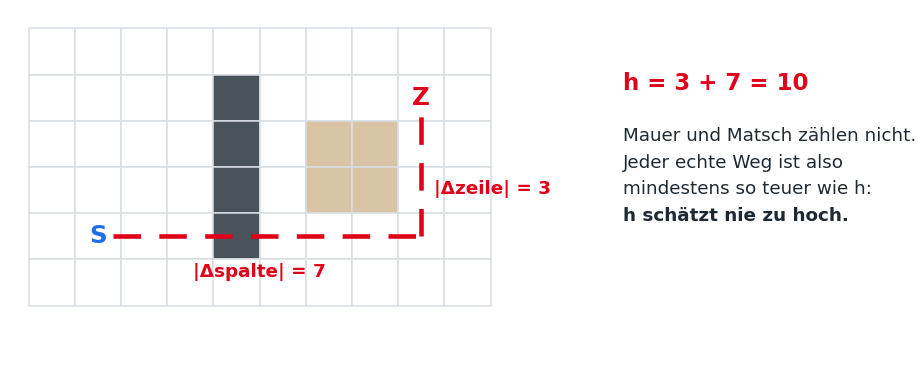

**Aufgabe:** Ergänzen Sie `manhattan`. Den Betrag liefert `abs(...)`.

In [ ]:
def manhattan(u, ziel):
    """Geschätzte Restkosten von u bis ziel."""
    (z1, s1), (z2, s2) = u, ziel
    # TODO: |Δzeile| + |Δspalte|
    return ...

In [ ]:
assert manhattan((4, 1), (1, 8)) == 10, "Beispiel aus der Abbildung: 3 + 7 = 10"
assert manhattan((1, 8), (4, 1)) == 10, "Die Richtung darf keine Rolle spielen."
assert manhattan(karte.start, karte.ziel) == 15
print("✓ manhattan korrekt")

## Teil 3: A\*

A\* sortiert `offen` nach $f = g + h$: bisherige Kosten plus geschätzte
Restkosten.

**Aufgabe:** Vervollständigen Sie `astar`. Übernehmen Sie dazu die
Schleife aus Ihrer `dijkstra` und ändern Sie, was für A\* nötig ist. `h`
ist die Heuristik als Funktion, aufgerufen wird sie mit `h(v, ziel)`.

In [ ]:
def astar(karte, start, ziel, h):
    g = {start: 0}
    vorgaenger = {start: None}
    offen = [(h(start, ziel), start)]   # Priorität f = g + h, am Start ist g = 0
    erledigt = set()

    # TODO: Schleife aus dijkstra übernehmen und anpassen
    ...

    return g, vorgaenger, erledigt

In [ ]:
g2, vorgaenger2, erledigt2 = astar(karte, karte.start, karte.ziel, manhattan)
assert karte.ziel in g2, "Das Ziel wurde nie erreicht. Ist die Schleife übernommen?"
print("Kosten bis Z:", g2[karte.ziel], "   expandierte Felder:", len(erledigt2))
assert g2[karte.ziel] == 23, "A* sollte denselben Preis finden wie Dijkstra."
assert len(erledigt2) < len(erledigt), "A* sollte weniger Felder expandieren."
print("✓ A* korrekt")

## Teil 4: Vergleich

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
karte.zeichne(erledigt, weg(vorgaenger, karte.ziel), "Dijkstra", ax=axes[0])
karte.zeichne(erledigt2, weg(vorgaenger2, karte.ziel), "A* mit Manhattan", ax=axes[1])
plt.show()

Und was macht A\*, wenn die Heuristik immer 0 schätzt?

In [ ]:
def null(u, ziel):
    return 0


g0, vorgaenger0, erledigt0 = astar(karte, karte.start, karte.ziel, null)
print("A* mit h = 0:", g0[karte.ziel], "Kosten,", len(erledigt0), "Felder expandiert")

**Fragen** (kurz schriftlich oder mit dem Nachbarn besprechen):

1.  Welche Felder spart A\* gegenüber Dijkstra ein? Woran liegt das?
2.  A\* expandiert weniger Felder. Warum ist der gefundene Weg trotzdem
    genauso billig?
3.  Was ist A\* mit $h = 0$? Was unterscheidet Dijkstra also noch von
    A\*?

## Bonus

**B1: Greedy-Suche.** Sortieren Sie `offen` nur nach der Schätzung
`h(v, ziel)`, ohne `g` (Greedy Best-First aus Kapitel 05). Schreiben Sie
`greedy` als Kopie von `astar` mit dieser einen Änderung. Wie teuer ist
der Weg, wie viele Felder werden expandiert?

In [ ]:
def greedy(karte, start, ziel, h):
    # TODO
    ...


# g3, vorgaenger3, erledigt3 = greedy(karte, karte.start, karte.ziel, manhattan)
# karte.zeichne(erledigt3, weg(vorgaenger3, karte.ziel), "Greedy")

**B2: Zu optimistisch ist besser als zu pessimistisch.** Die folgende
Zelle multipliziert die Heuristik mit einem Faktor $w$. Führen Sie sie
aus. Ab welchem $w$ wird der Weg teurer, und warum?

In [ ]:
for w in [0, 1, 2, 3, 5]:
    def h_mal_w(u, ziel):
        return w * manhattan(u, ziel)

    gw, vw, ew = astar(karte, karte.start, karte.ziel, h_mal_w)
    print(f"h = {w} · Manhattan:   Kosten {gw[karte.ziel]:3d},   {len(ew):3d} Felder expandiert")